# 2026 — DeepSeek-V4: Compressed Sparse Attention (CSA) and Heavily Compressed Attention (HCA)

**Paper:** DeepSeek-AI, *"DeepSeek-V4: Towards Highly Efficient Million-Token Context Intelligence"* (arXiv 2606.19348, 2026). DeepSeek-V4-Pro has 1.6T parameters (49B active) and V4-Flash has 284B (13B active), both with a **1M-token context**. At that length V4-Pro needs **27% of the per-token FLOPs and 10% of the KV cache** of DeepSeek-V3.2 (V4-Flash: 10% and 7%).

V3.2's sparse attention (notebook 75) still keeps one KV entry per token. V4 also **compresses the sequence** itself. Every attention layer is shared-KV multi-query attention (each cached entry is both key and value), with RMSNorm on queries and KV, and a learnable **attention sink**. The layers come in two kinds, interleaved after a couple of sliding-window layers:

**CSA (compression rate $m=4$, then sparse selection).** Merge every $m$ tokens into one entry with a learned, *per-channel* softmax pooling over $2m$ overlapping positions (block $i$ pools its own $m$ tokens plus the previous block's $m$, so nothing is cut apart at block boundaries):

$$C^{Comp}_i = \sum_{j\in\text{block } i} S^a_j \odot C^a_j + \sum_{j\in\text{block } i-1} S^b_j \odot C^b_j,\qquad [S^a; S^b] = \operatorname{softmax}_{\text{per channel}}([Z^a + B^a; Z^b + B^b])$$

A **lightning indexer**, $I_{t,s} = \sum_h w_{t,h}\,\operatorname{ReLU}(q^I_{t,h}\cdot K^I_s)$, then picks the top-$k$ compressed blocks per query ($k=512$ in V4-Flash, $1024$ in Pro).

**HCA (heavy compression, $m'=128$, dense).** Non-overlapping 128-token blocks pooled the same way. There are so few entries that every query attends to all of them, with no indexer.

**Sliding window ($n_{win}=128$).** A query can't see the (incomplete) block it sits in, so every layer also attends to the most recent raw tokens.

**Attention sink.** A learnable per-head logit $z'_h$ in the softmax denominator, $s_{h,i,j} = e^{z_{h,i,j}} / (\sum_k e^{z_{h,i,k}} + e^{z'_h})$, lets a head attend to "nothing".

We implement all of this at toy scale ($m=4$, $m'=16$, window 16), compare global-layer types on long-context recall, and account for the KV cache.

![Diagram: DeepSeek-V4: compressed sparse attention (CSA) and heavily compressed attention (HCA)](https://raw.githubusercontent.com/babushkai/neuralnetwork/main/assets/diagrams/78_2026_compressed_sparse_attention.png)

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


In [2]:
class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-6): super().__init__(); self.w = nn.Parameter(torch.ones(d)); self.eps = eps
    def forward(self, x): return self.w * x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps)

class Compressor(nn.Module):
    """Learned per-channel softmax pooling of blocks of m tokens. overlap=True is CSA (2m positions), False is HCA."""
    def __init__(self, d, c, m, overlap):
        super().__init__()
        self.m, self.overlap = m, overlap
        self.Ca, self.Za = nn.Linear(d, c, bias=False), nn.Linear(d, c, bias=False)
        self.Ba = nn.Parameter(torch.zeros(m, c))
        if overlap: self.Cb, self.Zb, self.Bb = nn.Linear(d, c, bias=False), nn.Linear(d, c, bias=False), nn.Parameter(torch.zeros(m, c))
        self.norm = RMSNorm(c)
    def forward(self, h):                                          # h: (B, T, d) -> (B, T//m, c)
        B, T, _ = h.shape; m, nb = self.m, T // self.m
        Ca = self.Ca(h).view(B, nb, m, -1); Za = self.Za(h).view(B, nb, m, -1) + self.Ba
        if not self.overlap:
            return self.norm((Za.softmax(2) * Ca).sum(2))
        Cb = self.Cb(h).view(B, nb, m, -1); Zb = self.Zb(h).view(B, nb, m, -1) + self.Bb
        Cb = torch.cat([torch.zeros_like(Cb[:, :1]), Cb[:, :-1]], 1)                     # block i uses block i-1's b-half
        Zb = torch.cat([torch.full_like(Zb[:, :1], float("-inf")), Zb[:, :-1]], 1)      # block 0 has no previous block
        S = torch.cat([Za, Zb], 2).softmax(2)                                            # softmax over 2m positions, per channel
        return self.norm((S * torch.cat([Ca, Cb], 2)).sum(2))

class V4Attention(nn.Module):
    """mode: 'window' | 'dense' | 'csa' | 'hca'. Shared-KV MQA with a sink; compressed modes also see the window."""
    def __init__(self, d, mode, n_heads=4, c=32, d_c=48, m=4, m_heavy=16, window=16, topk=8, idx_heads=2, idx_dim=16):
        super().__init__()
        self.mode, self.h, self.c, self.window, self.topk = mode, n_heads, c, window, topk
        self.W_DQ, self.W_UQ = nn.Linear(d, d_c, bias=False), nn.Linear(d_c, n_heads * c, bias=False)   # low-rank query path
        self.q_norm, self.kv_raw, self.kv_norm = RMSNorm(c), nn.Linear(d, c, bias=False), RMSNorm(c)
        self.sink = nn.Parameter(torch.zeros(n_heads))                                    # z'_h
        self.out = nn.Linear(n_heads * c, d, bias=False)
        self.m = m if mode == "csa" else m_heavy
        if mode in ("csa", "hca"): self.comp = Compressor(d, c, self.m, overlap=(mode == "csa"))
        if mode == "csa":
            self.W_IUQ, self.W_w = nn.Linear(d_c, idx_heads * idx_dim, bias=False), nn.Linear(d, idx_heads, bias=False)
            self.W_IK = nn.Linear(c, idx_dim, bias=False)   # indexer keys from the compressed entries (a simplification)
            self.ih, self.idim = idx_heads, idx_dim
        self.sparse_on, self.kl = True, torch.tensor(0.0)

    def forward(self, h):
        B, T, _ = h.shape
        cq = self.W_DQ(h)
        q = self.q_norm(self.W_UQ(cq).view(B, T, self.h, self.c)).transpose(1, 2)        # (B, h, T, c)
        raw = self.kv_norm(self.kv_raw(h))                                                # (B, T, c): uncompressed entries
        t = torch.arange(T, device=h.device)
        raw_ok = t[None, :] <= t[:, None]
        if self.mode != "dense": raw_ok = raw_ok & (t[:, None] - t[None, :] < self.window)
        logits = [(q @ raw.unsqueeze(1).transpose(-2, -1)).masked_fill(~raw_ok, float("-inf"))]
        values = [raw]
        if self.mode in ("csa", "hca"):
            comp = self.comp(h)                                                           # (B, nb, c)
            nb = comp.shape[1]; s = torch.arange(nb, device=h.device)
            comp_ok = (s[None, :] < (t[:, None] // self.m)).expand(B, T, nb)              # only complete, earlier blocks
            cl = q @ comp.unsqueeze(1).transpose(-2, -1)                                  # (B, h, T, nb)
            if self.mode == "csa":
                # lightning indexer; its inputs are detached so its KL loss trains only the indexer (as in DeepSeek-V3.2)
                qi = self.W_IUQ(cq.detach()).view(B, T, self.ih, self.idim); ki = self.W_IK(comp.detach())
                I = (self.W_w(h.detach()).unsqueeze(-1) * F.relu(torch.einsum("bthd,bsd->bths", qi, ki))).sum(2)
                I = I.masked_fill(~comp_ok, float("-inf"))
                sel = comp_ok
                if self.sparse_on:
                    top = I.topk(min(self.topk, nb), -1).indices
                    sel = torch.zeros_like(comp_ok).scatter_(-1, top, True) & comp_ok
                with torch.no_grad():                                                     # indexer target: main attention over blocks
                    tgt = cl.detach().masked_fill(~sel.unsqueeze(1), float("-inf")).softmax(-1).nan_to_num(0).sum(1)
                    tgt = tgt / tgt.sum(-1, keepdim=True).clamp_min(1e-9)
                logp = I.masked_fill(~sel, -1e9).log_softmax(-1)   # finite fill: rows with no complete block yet must not create NaN gradients
                rows = sel.any(-1)
                self.kl = ((tgt * (tgt.clamp_min(1e-9).log() - logp)).sum(-1) * rows).sum() / rows.sum().clamp_min(1)
                comp_ok = sel
            logits.append(cl.masked_fill(~comp_ok.unsqueeze(1), float("-inf"))); values.append(comp)
        allz = torch.cat(logits, -1) / math.sqrt(self.c)
        allz = torch.cat([allz, self.sink.view(1, -1, 1, 1).expand(B, -1, T, 1)], -1)    # sink logit: in the denominator only
        a = allz.softmax(-1)[..., :-1]
        o = a @ torch.cat(values, 1).unsqueeze(1)                                         # shared KV: entries are keys and values
        return self.out(o.transpose(1, 2).reshape(B, T, -1))

class LM(nn.Module):
    def __init__(self, modes, d=64, T=256):
        super().__init__()
        self.emb, self.pos = nn.Embedding(VOC, d), nn.Embedding(T, d)
        self.attn = nn.ModuleList([V4Attention(d, mo) for mo in modes])
        self.mlp = nn.ModuleList([nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d)) for _ in modes])
        self.n1 = nn.ModuleList([RMSNorm(d) for _ in modes]); self.n2 = nn.ModuleList([RMSNorm(d) for _ in modes])
        self.head = nn.Linear(d, VOC)
    def forward(self, x):
        h = self.emb(x) + self.pos(torch.arange(x.shape[1], device=x.device))
        for a, m, n1, n2 in zip(self.attn, self.mlp, self.n1, self.n2): h = h + a(n1(h)); h = h + m(n2(h))
        return self.head(h[:, -2 * NQ + 1::2])
    def kl(self): return sum(a.kl for a in self.attn if a.mode == "csa")

## Task: recall in a 256-token context
Same multi-query recall as notebook 75, at twice the length. Note: we use learned absolute positions for simplicity, where V4 uses partial RoPE on the last 64 dimensions.

In [3]:
NK, NV, P, NQ, T_ctx = 16, 16, 8, 4, 256
FILL = NK + NV; QRY = FILL + 1; VOC = QRY + 1
def batch(B):
    x = torch.full((B, T_ctx), FILL)
    keys = torch.rand(B, NK).argsort(1)[:, :P]; vals = torch.randint(NK, NK + NV, (B, P))
    slots = torch.rand(B, (T_ctx - 2 * NQ) // 2).argsort(1)[:, :P] * 2 + torch.randint(0, 2, (B, 1))   # pairs may straddle block edges
    slots = slots.clamp(max=T_ctx - 2 * NQ - 2)
    x.scatter_(1, slots, keys); x.scatter_(1, slots + 1, vals)
    pick = torch.rand(B, P).argsort(1)[:, :NQ]
    x[:, -2 * NQ:] = torch.stack([torch.full((B, NQ), QRY), keys.gather(1, pick)], 2).view(B, 2 * NQ)
    return x.to(device), vals.gather(1, pick).to(device)

def fit(model, steps, lr=2e-3, kl_w=0.0):
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, lr, total_steps=steps, pct_start=0.1)
    for s in range(steps):
        x, y = batch(64)
        loss = F.cross_entropy(model(x).reshape(-1, VOC), y.reshape(-1)) + kl_w * model.kl()
        opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
    return model

@torch.no_grad()
def accuracy(model):
    model.eval(); x, y = batch(1000); a = (model(x).argmax(-1) == y).float().mean().item(); model.train(); return a

## Compare global-layer types
Layer 1 is always a sliding-window layer, as in V4-Flash, which handles the local key→value binding. Layer 2 is the global layer under test. CSA is trained the way V4 introduces sparsity: first with dense attention over all compressed blocks while the indexer learns to imitate it (KL loss), then with top-$k$ selection switched on.

In [4]:
results, models = {}, {}
for name, modes in [("dense (all raw tokens)", ["window", "dense"]), ("window only", ["window", "window"]),
                    ("HCA (m'=16, dense over blocks)", ["window", "hca"])]:
    seed_everything(0); t0 = time.time()
    models[name] = fit(LM(modes).to(device), 1500); results[name] = accuracy(models[name])
    print(f"{name:34s} accuracy {results[name]:.3f}  ({time.time() - t0:.0f}s)")

seed_everything(0); t0 = time.time()
csa = LM(["window", "csa"]).to(device)
for a in csa.attn: a.sparse_on = False
fit(csa, 1100, kl_w=1.0)                                                              # dense over compressed blocks + indexer warm-up
results["CSA dense over blocks (warm-up)"] = accuracy(csa)
for a in csa.attn: a.sparse_on = True
results["CSA top-8 blocks (m=4)"] = accuracy(csa)
fit(csa, 400, lr=1e-3, kl_w=1.0)                                                      # sparse stage
results["CSA top-8 blocks, after sparse training"] = accuracy(csa); models["CSA"] = csa
for k in list(results)[-3:]: print(f"{k:42s} accuracy {results[k]:.3f}")
print(f"({time.time() - t0:.0f}s)")

dense (all raw tokens)             accuracy 0.999  (147s)


window only                        accuracy 0.135  (116s)


HCA (m'=16, dense over blocks)     accuracy 0.831  (154s)


CSA dense over blocks (warm-up)            accuracy 0.971
CSA top-8 blocks (m=4)                     accuracy 0.972
CSA top-8 blocks, after sparse training    accuracy 0.970
(173s)


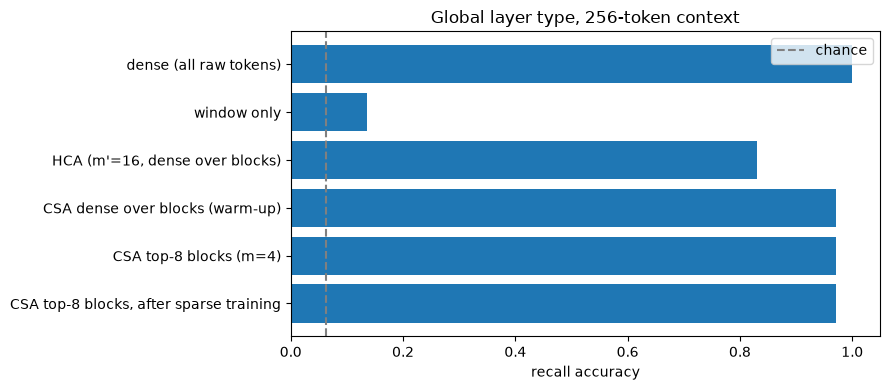

In [5]:
plt.figure(figsize=(9, 4))
plt.barh(list(results)[::-1], list(results.values())[::-1]); plt.axvline(1 / NV, c="gray", ls="--", label="chance")
plt.xlabel("recall accuracy"); plt.legend(); plt.title(f"Global layer type, {T_ctx}-token context"); plt.tight_layout(); plt.show()

## How many entries does each query attend to, and how big is the cache?

In [6]:
def entries(mode, T, m=4, m_heavy=128, window=128, topk=512):
    return {"dense": T, "window": window, "csa": topk + window, "hca": T // m_heavy + window}[mode]
def cache(mode, T, m=4, m_heavy=128, window=128):
    return {"dense": T, "window": window, "csa": T // m + window, "hca": T // m_heavy + window}[mode]
print("at toy scale (T=256, m=4, m'=16, window=16, top-8):")
for mode in ["dense", "csa", "hca", "window"]:
    print(f"  {mode:6s} attends to {entries(mode, 256, m_heavy=16, window=16, topk=8):4d} entries | caches {cache(mode, 256, m_heavy=16, window=16):4d}")
T = 1_000_000
print(f"\nat V4-Flash settings, T = {T:,} (m=4, m'=128, window=128, top-512):")
for mode in ["dense", "csa", "hca"]:
    print(f"  {mode:6s} attends to {entries(mode, T):>9,} entries | caches {cache(mode, T):>9,} entries per layer ({cache(mode, T) / T:.1%} of dense)")
print("V4 also stores most cache dimensions in FP8 and shares one KV head across all query heads,")
print("which is how it reaches ~2% of a BF16 GQA-8 baseline's KV cache at 1M tokens (paper's estimate).")

at toy scale (T=256, m=4, m'=16, window=16, top-8):
  dense  attends to  256 entries | caches  256
  csa    attends to   24 entries | caches   80
  hca    attends to   32 entries | caches   32
  window attends to   16 entries | caches   16

at V4-Flash settings, T = 1,000,000 (m=4, m'=128, window=128, top-512):
  dense  attends to 1,000,000 entries | caches 1,000,000 entries per layer (100.0% of dense)
  csa    attends to       640 entries | caches   250,128 entries per layer (25.0% of dense)
  hca    attends to     7,940 entries | caches     7,940 entries per layer (0.8% of dense)
V4 also stores most cache dimensions in FP8 and shares one KV head across all query heads,
which is how it reaches ~2% of a BF16 GQA-8 baseline's KV cache at 1M tokens (paper's estimate).


## Takeaways
- **Compression** shrinks the cache itself (4× in CSA, 128× in HCA) and **sparsity** shrinks per-query work (top-$k$ blocks). The sliding window keeps exact local detail, and the sink lets heads abstain.
- In our test, the overlapping 4-token pooling keeps each key–value pair recoverable, so CSA with only 8 of 64 blocks can retrieve. HCA's 16-token pooling is much coarser, which suits a global summary; V4 interleaves the two so the model gets both precise and coarse long-range views.
- Compare notebooks 67 (MLA: compress each token's KV), 54 (DSA: select tokens) and this one (compress *and* select along the sequence). That is the progression of DeepSeek's attention from 2024 to 2026.